# 01 · Problema y exploración

En este notebook planteamos el problema de las cancelaciones de reservas, describimos el dataset *Hotel Booking Demand* y lo exploramos antes de preparar los datos para los modelos.

## 1. El problema y los datos

### 1.1 Por qué le cuestan tanto las cancelaciones a un hotel

Una noche de hotel es un producto que se vence: si la habitación queda vacía hoy, esa noche ya no se puede vender después. Por eso las cancelaciones le salen caras a un hotel. Mientras la reserva está activa, la habitación queda bloqueada y se deja de ofrecer a otros clientes, y si el cliente cancela a última hora o simplemente no llega (*no-show*), muchas veces ya no hay tiempo de volverla a vender. Esa plata se pierde.

Los hoteles se defienden de dos formas, y las dos tienen su costo:

- **Sobreventa (*overbooking*).** Venden más habitaciones de las que tienen, contando con que algunos clientes van a cancelar. Si se equivocan y llegan todos, toca reubicar huéspedes en otro hotel, pagar ese traslado y quedar mal con el cliente.
- **Políticas más estrictas.** Piden depósitos que no se devuelven o cobran por cancelar. Eso baja las cancelaciones, pero también puede espantar a clientes que sí iban a llegar.

Las dos funcionan mejor si el hotel sabe, en el momento en que entra una reserva, qué tan probable es que se cancele. Ahí entra este trabajo: nos ponemos en el lugar del área comercial de un hotel que quiere anticipar las cancelaciones y entender qué tipos de reservas recibe, para tratarlas distinto en vez de aplicarles a todas la misma política.

Un modelo que anticipe cancelaciones se puede equivocar de dos maneras. Si dice que una reserva no se va a cancelar y sí se cancela, el hotel no se prepara y la habitación puede quedar vacía. Si dice que se va a cancelar y el cliente sí llega, el hotel puede sobrevender esa habitación y terminar reubicando a alguien. Ninguno de los dos errores es gratis, y por eso en el componente supervisado miramos el Recall (de las cancelaciones reales, cuántas detecta el modelo), la Precision (de las reservas que marca como canceladas, cuántas lo eran), el F1, que combina las dos, y el ROC-AUC, que mide qué tan bien ordena el modelo las reservas de más a menos riesgo sin depender de un umbral.

### 1.2 Objetivo

Anticipar, con la información que se tiene en el momento de hacer la reserva, si una reserva se va a cancelar, y encontrar grupos de reservas con un comportamiento parecido, para proponerle al hotel estrategias que reduzcan las cancelaciones o lo que le cuestan.

Para eso nos propusimos:

1. Entender qué variables se relacionan con la cancelación y cuáles no se pueden usar porque solo se conocen después de reservar.
2. Entrenar y comparar dos modelos supervisados, una regresión logística y un bosque aleatorio, con F1, Recall, Precision y ROC-AUC.
3. Agrupar las reservas con dos métodos, K-Means y agrupamiento jerárquico, sin usar `is_canceled`, y describir qué tiene cada grupo.
4. Comparar lo que aporta cada enfoque y convertir los resultados en recomendaciones para el hotel.

### 1.3 Preguntas que vamos a responder

1. ¿Qué características de una reserva permiten anticipar que se va a cancelar?
2. ¿Qué tan bien se puede predecir una cancelación solo con lo que se sabe al momento de reservar?
3. ¿Qué perfiles de reservas existen?
4. ¿Cómo se relacionan esos perfiles con las cancelaciones y qué estrategias sugieren?

Las dos primeras las responde el componente supervisado (notebook 03), la tercera el no supervisado (notebook 04) y la cuarta junta los dos. Las ocho preguntas de comparación que pide el enunciado las respondemos en el notebook 05.

### 1.4 El dataset

Trabajamos con **Hotel Booking Demand**, publicado en Kaggle por Jesse Mostipak ([enlace](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)). Los datos vienen del artículo de Nuno Antonio, Ana de Almeida y Luis Nunes, *Hotel booking demand datasets* (*Data in Brief*, vol. 22, 2019, [doi](https://doi.org/10.1016/j.dib.2018.11.083)). Ellos los sacaron del sistema de gestión de reservas de dos hoteles de Portugal: un hotel de playa en el Algarve (*Resort Hotel*) y un hotel de ciudad en Lisboa (*City Hotel*). Cada fila es una reserva con llegada prevista entre julio de 2015 y agosto de 2017, haya llegado el cliente o no.

**Tipo de fuente: secundaria.** Los datos no los recogimos nosotros: salieron del sistema de los hoteles y los autores los anonimizaron antes de publicarlos. Por eso los hoteles no tienen nombre y la agencia, la empresa y los tipos de habitación vienen como códigos. Y por lo mismo no sabemos con detalle en qué momento se llenó cada campo. Por ejemplo, no sabemos si el país del cliente se registra al reservar o se corrige cuando llega al hotel, y eso importa para decidir si lo podemos usar en el modelo.

También hay que tener presente desde ya que son solo dos hoteles de un mismo país y de antes de la pandemia. Lo que encontremos describe a esos dos hoteles en esos años y no se puede pasar sin más a otros hoteles.

El archivo lo dejamos en `data/raw/hotel_bookings.csv.zip`, comprimido tal como se descarga de Kaggle.

### 1.5 Diccionario de variables

Las 32 columnas, agrupadas por tema. Las descripciones las sacamos del artículo original.

| Tema | Variable | Qué es |
|---|---|---|
| Resultado | `is_canceled` | **Variable objetivo.** 1 si la reserva se canceló y 0 si no |
| | `reservation_status` | Último estado de la reserva: *Canceled* (cancelada), *Check-Out* (el cliente llegó y ya se fue) o *No-Show* (el cliente no llegó) |
| | `reservation_status_date` | Fecha en que se registró ese último estado |
| Reserva | `hotel` | *Resort Hotel* (Algarve) o *City Hotel* (Lisboa) |
| | `lead_time` | Días entre el día en que se hizo la reserva y la fecha de llegada |
| | `deposit_type` | Depósito que se pidió: *No Deposit* (ninguno), *Non Refund* (por el valor total de la estadía, sin devolución) o *Refundable* (por menos del valor total) |
| | `days_in_waiting_list` | Días que la reserva estuvo en lista de espera antes de que se le confirmara al cliente |
| | `adr` | Tarifa diaria promedio (*Average Daily Rate*): lo que se cobra por alojamiento dividido entre el número de noches |
| | `meal` | Plan de comidas: *BB* (desayuno), *HB* (desayuno y otra comida), *FB* (las tres comidas), *SC* o *Undefined* (sin plan) |
| | `required_car_parking_spaces` | Parqueaderos que pidió el cliente |
| | `total_of_special_requests` | Pedidos especiales del cliente, como cama doble o un piso alto |
| Llegada y estadía | `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month` | Año, mes, semana del año y día del mes de la llegada |
| | `stays_in_weekend_nights` | Noches de sábado o domingo que incluye la reserva |
| | `stays_in_week_nights` | Noches de lunes a viernes que incluye la reserva |
| Huéspedes | `adults`, `children`, `babies` | Número de adultos, niños y bebés |
| | `country` | País de origen del cliente, como código (por ejemplo `PRT` es Portugal y `GBR` el Reino Unido) |
| | `is_repeated_guest` | 1 si el cliente ya se había hospedado en el hotel |
| | `previous_cancellations` | Reservas anteriores que el cliente canceló |
| | `previous_bookings_not_canceled` | Reservas anteriores que el cliente no canceló |
| | `customer_type` | *Transient* (reserva suelta), *Transient-Party* (suelta, pero ligada a otra reserva), *Group* (de un grupo) o *Contract* (con un contrato o un cupo asignado) |
| Canal | `market_segment` | Segmento de mercado, por ejemplo *Online TA* (agencias en línea), *Offline TA/TO* (agencias y operadores turísticos tradicionales), *Direct*, *Groups* o *Corporate* |
| | `distribution_channel` | Canal por el que llegó la reserva (*TA/TO*, *Direct*, *Corporate*, *GDS* o *Undefined*) |
| | `agent` | Código de la agencia de viajes que hizo la reserva |
| | `company` | Código de la empresa que hizo la reserva o la paga |
| Habitación | `reserved_room_type` | Tipo de habitación reservada (código anonimizado) |
| | `assigned_room_type` | Tipo de habitación que se le asignó al final. Puede ser distinta de la reservada, por sobreventa o porque el cliente lo pidió |
| | `booking_changes` | Cambios que se le hicieron a la reserva desde que se registró hasta el check-in o la cancelación |

El primer grupo hay que leerlo con cuidado. `reservation_status` dice qué pasó con la reserva, o sea que repite la respuesta que queremos predecir, y su fecha es la del día en que se canceló o terminó la estadía. Como el modelo se usaría cuando entra una reserva, la regla que acordamos es que una variable solo entra si se conoce en ese momento. Con esa regla también quedan en duda columnas como `assigned_room_type` y `booking_changes`, que pueden cambiar hasta el día de la llegada. Eso lo revisamos con datos en la sección 3, y el notebook 02 deja por fuera las que no cumplan.

### 1.6 Carga de los datos

Leemos el CSV directamente desde el `.zip` (pandas lo descomprime al leerlo). Arriba dejamos las constantes que usamos en todo el notebook: la semilla, la ruta de los datos, la variable objetivo y los colores de las gráficas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
RUTA_DATOS = Path("../data/raw/hotel_bookings.csv.zip")
OBJETIVO = "is_canceled"

MESES = ["January", "February", "March", "April", "May", "June", "July",
         "August", "September", "October", "November", "December"]

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"
COLORES_HOTEL = {"City Hotel": COLOR_PRINCIPAL, "Resort Hotel": COLOR_SECUNDARIO}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [2]:
reservas = pd.read_csv(RUTA_DATOS)

canceladas = reservas[OBJETIVO].sum()
print(f"{len(reservas):,} reservas y {reservas.shape[1]} columnas")
print(f"Canceladas: {canceladas:,} ({canceladas / len(reservas):.1%})")

119,390 reservas y 32 columnas
Canceladas: 44,224 (37.0%)


In [3]:
reservas.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Cada fila es una reserva y las columnas son las del diccionario. La fecha de llegada viene partida en cuatro columnas (año, mes escrito en inglés, número de semana y día del mes), así que para ver qué periodo cubren los datos toca unirla.

### 1.7 Qué periodo cubren los datos

Unimos año, mes y día en una sola fecha de llegada y contamos las reservas por hotel y por año. Aquí cuentan todas las reservas, canceladas o no.

In [4]:
def fecha_de_llegada(datos):
    """Une las columnas de año, mes y día en una sola fecha de llegada."""
    numero_de_mes = {mes: numero for numero, mes in enumerate(MESES, start=1)}
    partes = pd.DataFrame({
        "year": datos["arrival_date_year"],
        "month": datos["arrival_date_month"].map(numero_de_mes),
        "day": datos["arrival_date_day_of_month"],
    })
    return pd.to_datetime(partes)


llegada = fecha_de_llegada(reservas)

resumen_hoteles = (
    reservas.assign(llegada=llegada)
    .groupby("hotel")
    .agg(reservas=("hotel", "size"),
         primera_llegada=("llegada", "min"),
         ultima_llegada=("llegada", "max"))
)
resumen_hoteles["porcentaje"] = (resumen_hoteles["reservas"] / len(reservas) * 100).round(1)
resumen_hoteles

,reservas,primera_llegada,ultima_llegada,porcentaje
hotel,,,,
City Hotel,79330,2015-07-01,2017-08-31,66.4
Resort Hotel,40060,2015-07-01,2017-08-31,33.6


In [5]:
reservas_por_anio = llegada.groupby(llegada.dt.year).agg(
    reservas="size",
    meses_con_datos=lambda fechas: fechas.dt.month.nunique(),
)
reservas_por_anio.index.name = "año"
reservas_por_anio

,reservas,meses_con_datos
año,,
2015,21996,6
2016,56707,12
2017,40687,8


**¿Qué vemos?**

- Los dos hoteles tienen llegadas en todo el periodo, del 1 de julio de 2015 al 31 de agosto de 2017. El City Hotel tiene dos de cada tres reservas (79.330, el 66,4 %) y el Resort Hotel el resto (40.060).
- Solo 2016 está completo. De 2015 hay 6 meses (julio a diciembre) y de 2017 hay 8 (enero a agosto). Por eso los totales por año no se pueden comparar: que 2016 tenga 56.707 reservas y 2015 solo 21.996 no quiere decir que la demanda se haya disparado, sino que a 2015 le faltan seis meses.

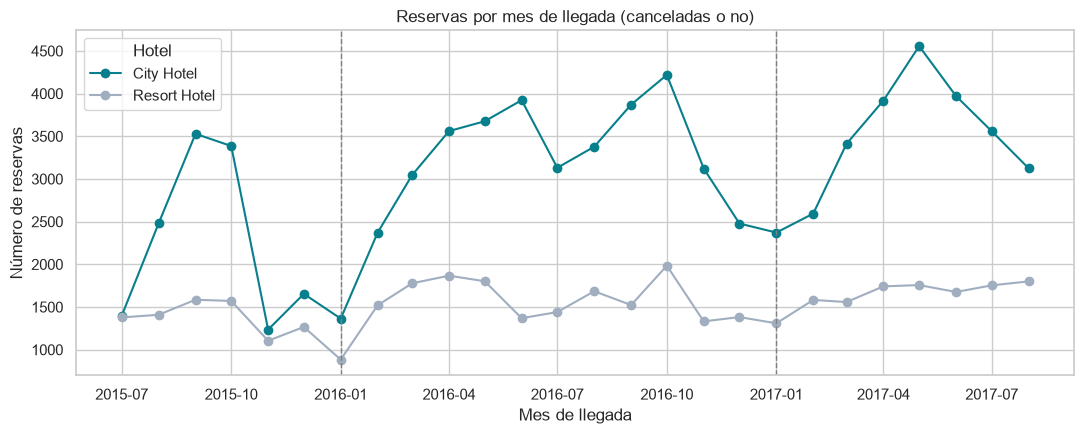

City Hotel: el mes con menos reservas es 2015-11 (1,235) y el de más es 2017-05 (4,556)
Resort Hotel: el mes con menos reservas es 2016-01 (884) y el de más es 2016-10 (1,984)


In [6]:
reservas_por_mes = (
    reservas.assign(mes=llegada.dt.to_period("M").dt.to_timestamp())
    .groupby(["hotel", "mes"])
    .size()
    .rename("reservas")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 4.5))
for hotel, datos in reservas_por_mes.groupby("hotel"):
    ax.plot(datos["mes"], datos["reservas"], marker="o", color=COLORES_HOTEL[hotel], label=hotel)
for anio in (2016, 2017):
    ax.axvline(pd.Timestamp(anio, 1, 1), color="gray", linestyle="--", linewidth=1)
ax.set_title("Reservas por mes de llegada (canceladas o no)")
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("Número de reservas")
ax.legend(title="Hotel")
plt.tight_layout()
plt.show()

for hotel, datos in reservas_por_mes.groupby("hotel"):
    menor = datos.loc[datos["reservas"].idxmin()]
    mayor = datos.loc[datos["reservas"].idxmax()]
    print(f"{hotel}: el mes con menos reservas es {menor['mes']:%Y-%m} ({menor['reservas']:,}) "
          f"y el de más es {mayor['mes']:%Y-%m} ({mayor['reservas']:,})")

**¿Qué vemos?**

- El City Hotel no solo tiene más reservas, también cambia mucho más de un mes a otro: va de 1.235 reservas en noviembre de 2015 a 4.556 en mayo de 2017. Baja hacia diciembre y enero, y tiene sus picos en primavera (abril a junio) y en septiembre-octubre. El Resort Hotel se mueve en un rango más corto, entre 884 reservas (enero de 2016) y 1.984 (octubre de 2016).
- En julio y agosto de 2015 el City Hotel tiene bastantes menos reservas que en los mismos meses de 2016 y 2017. Con estos datos no sabemos si es que tenía menos demanda o si el registro arrancó incompleto, así que tampoco sacamos conclusiones de tendencia entre años.
- Como la demanda sube y baja tanto según el mes, es posible que el mes de llegada también pese en las cancelaciones. Eso no lo podemos concluir de esta gráfica, que cuenta todas las reservas juntas; lo miramos en la sección 3.

### 1.8 Cierre de la sección

- El problema es grande para estos dos hoteles: de 119.390 reservas se cancelaron 44.224, el 37,0 %.
- Los datos cubren 26 meses, pero solo 2016 está completo, y son de solo dos hoteles de Portugal. Lo que encontremos vale para ellos y no se puede generalizar sin más.
- Para predecir solo podemos usar lo que se sabe al momento de reservar, y el dataset trae columnas que se llenan después.

Antes de mirar las cancelaciones hay que revisar qué tan limpios vienen los datos, y eso es lo que hacemos en la sección 2.